In [48]:
#Import Libraries
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

#Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Libraries imported successfully!
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [49]:
#Set Artifacts Directory
folder = '/content/drive/MyDrive/Diabetes-Prediction/artifacts'

print("Artifacts folder:", folder)

#Load All Model Metrics
# Load metrics CSV files

logistic = pd.read_csv(
    os.path.join(folder, 'logistic_regression_metrics.csv')
)

random_forest = pd.read_csv(
    os.path.join(folder, 'random_forest_metrics.csv')
)

svm = pd.read_csv(
    os.path.join(folder, 'svm_metrics.csv')
)

print("All model metrics loaded successfully!")

Artifacts folder: /content/drive/MyDrive/Diabetes-Prediction/artifacts
All model metrics loaded successfully!


In [50]:
#Combine All Metrics
logistic['Model'] = 'Logistic Regression'
random_forest['Model'] = 'Random Forest'
svm['Model'] = 'SVM'

comparison = pd.concat(
    [logistic, random_forest, svm],
    ignore_index=True
)

display(comparison)

,Metric,Score,Model
0,Accuracy,0.977500,Logistic Regression
1,Precision,0.983943,Logistic Regression
2,Recall,0.989238,Logistic Regression
3,F1-score,0.986583,Logistic Regression
4,Balanced Accuracy,0.953397,Logistic Regression
5,Specificity,0.917557,Logistic Regression
6,Accuracy,0.973000,Random Forest
7,Precision,0.980125,Random Forest
8,Recall,0.987743,Random Forest
9,F1-score,0.983919,Random Forest


In [51]:
#Compare Model Performance
comparison_table = comparison.pivot(
    index='Model',
    columns='Metric',
    values='Score'
)

display(comparison_table.round(4))

Metric,Accuracy,Balanced Accuracy,F1-score,Precision,Recall,Specificity
Model,,,,,,
Logistic Regression,0.9775,0.9534,0.9866,0.9839,0.9892,0.9176
Random Forest,0.9730,0.9427,0.9839,0.9801,0.9877,0.8977
SVM,0.9760,0.9488,0.9857,0.9822,0.9892,0.9084


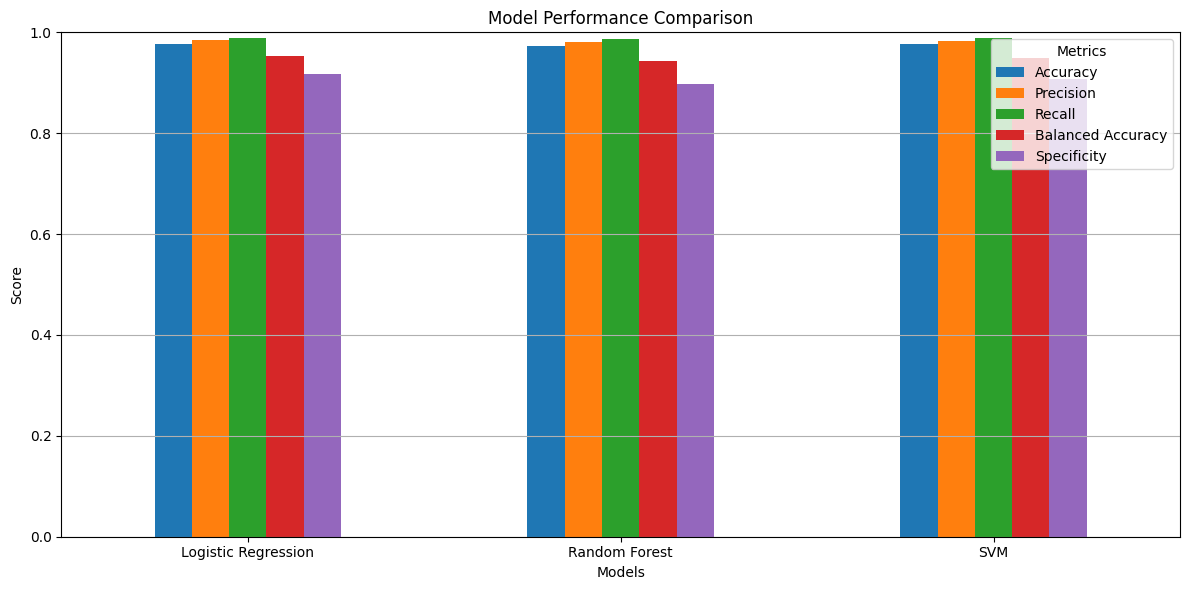

In [52]:
#Performance Comparison Graph
metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-Score',
    'Balanced Accuracy',
    'Specificity'
]

available_metrics = [
    metric for metric in metrics
    if metric in comparison_table.columns
]

comparison_table[available_metrics].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.xlabel("Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [53]:
#Find the Best Model
if 'F1-score' in comparison_table.columns:
    best_f1 = comparison_table['F1-score'].idxmax()
    print("Best Model based on F1-Score:", best_f1)

if 'Accuracy' in comparison_table.columns:
    best_accuracy = comparison_table['Accuracy'].idxmax()
    print("Best Model based on Accuracy:", best_accuracy)

Best Model based on F1-Score: Logistic Regression
Best Model based on Accuracy: Logistic Regression


In [54]:
#Save Comparison Results
comparison_table.to_csv(
    os.path.join(folder, 'model_comparison.csv')
)

print("Comparison results saved successfully!")

Comparison results saved successfully!


In [55]:
import os
import pandas as pd

# 1. Set Artifacts Directory
folder = '/content/drive/MyDrive/Diabetes-Prediction/artifacts'

# Map each comparison CSV to its feature set / experiment name
comparison_files = {
    'Experiment 1 (Default)': 'model_comparison.csv',
    'Experiment 2 (Version 5)': 'model_comparison (5).csv',
    'Experiment 3 (Version 8)': 'model_comparison (8).csv'
}

all_results = []

# 2. Load and combine all comparison CSVs
for exp_name, filename in comparison_files.items():
    filepath = os.path.join(folder, filename)
    df = pd.read_csv(filepath)

    # Standardize column names in case of capitalization differences ('F1-score' vs 'F1-Score')
    df.columns = [
        'F1-Score' if col.lower() == 'f1-score' else col
        for col in df.columns
    ]

    # If older files still have split F1 columns, merge them into one
    if 'F1-score' in df.columns and 'F1-Score' in df.columns:
        df['F1-Score'] = df['F1-Score'].fillna(df['F1-score'])
        df = df.drop(columns=['F1-score'])

    df['Feature_Set'] = exp_name
    all_results.append(df)

# Combine into a single master DataFrame
master_df = pd.concat(all_results, ignore_index=True)

# 3. Rank all Feature Sets & Models by F1-Score and Accuracy
master_df['Combined_Score'] = (master_df['F1-Score'] + master_df['Accuracy']) / 2
ranked_df = master_df.sort_values(by=['F1-Score', 'Accuracy'], ascending=False)

print("=== Full Ranking Across All Feature Sets & Models ===")
display(ranked_df[['Feature_Set', 'Model', 'F1-Score', 'Accuracy', 'Combined_Score']].round(4))

# 4. Print the Overall Best Winners
best_f1_row = master_df.loc[master_df['F1-Score'].idxmax()]
best_acc_row = master_df.loc[master_df['Accuracy'].idxmax()]
best_overall_row = master_df.loc[master_df['Combined_Score'].idxmax()]

print(f"\nBest by F1-Score: {best_f1_row['Model']} in {best_f1_row['Feature_Set']} ({best_f1_row['F1-Score']:.4f})")
print(f"Best by Accuracy: {best_acc_row['Model']} in {best_acc_row['Feature_Set']} ({best_acc_row['Accuracy']:.4f})")
print(f"Overall Best Combination: {best_overall_row['Model']} in {best_overall_row['Feature_Set']} (Avg: {best_overall_row['Combined_Score']:.4f})")


=== Full Ranking Across All Feature Sets & Models ===


,Feature_Set,Model,F1-Score,Accuracy,Combined_Score
0,Experiment 1 (Default),Logistic Regression,0.9866,0.9775,0.9820
6,Experiment 3 (Version 8),Logistic Regression,0.9863,0.9770,0.9816
3,Experiment 2 (Version 5),Logistic Regression,0.9860,0.9765,0.9812
8,Experiment 3 (Version 8),SVM,0.9859,0.9762,0.9811
2,Experiment 1 (Default),SVM,0.9857,0.9760,0.9809
7,Experiment 3 (Version 8),Random Forest,0.9854,0.9755,0.9804
5,Experiment 2 (Version 5),SVM,0.9850,0.9748,0.9799
4,Experiment 2 (Version 5),Random Forest,0.9846,0.9742,0.9794
1,Experiment 1 (Default),Random Forest,0.9839,0.9730,0.9785



Best by F1-Score: Logistic Regression in Experiment 1 (Default) (0.9866)
Best by Accuracy: Logistic Regression in Experiment 1 (Default) (0.9775)
Overall Best Combination: Logistic Regression in Experiment 1 (Default) (Avg: 0.9820)


In [56]:
# Save the Full Ranking Table to a CSV file
output_csv_path = os.path.join(folder, 'all_models_ranked_comparison.csv')
ranked_df[['Feature_Set', 'Model', 'F1-Score', 'Accuracy', 'Combined_Score']].round(4).to_csv(output_csv_path, index=False)

print(f"Ranked CSV saved successfully to: {output_csv_path}")


Ranked CSV saved successfully to: /content/drive/MyDrive/Diabetes-Prediction/artifacts/all_models_ranked_comparison.csv
